# DeepLabCut projects on the SCENE tables: a mouse example

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SCENE-Collaboration/SCENE-pipelines/blob/dev/examples/tutorials/02_dlc_ingestion.ipynb)

A lab that tracks its animals with DeepLabCut has projects full of labeled frames. This tutorial puts one on the
SCENE tables, next to the mice and sessions it belongs to, so that its keypoints and labels can be queried with
everything else the lab registers.

The DeepLabCut tables come from [dlc-scene](https://github.com/C-Achard/dlc-scene): a schema, `dlc`, that registers
on `SCENE_REGISTRY` like any other and hangs off the shared `Lab`. A lab pipeline calls it in one place
(HumanNeuroscience does it in its `register_dlc_project`); the rest is the shared layer and the lab's own tables.

| Layer | Tables | Holds |
|---|---|---|
| shared | `Lab`, `Project`, `Mouse`, `Session` | who was recorded, when, in which project |
| dlc | `DlcProject`, `KeypointSpec`, `HumanLabels`, ... | the DeepLabCut project, its keypoints and its labels |
| lab | `LabeledDataset` | which session each labeled dataset comes from |

**Before you start** (on Colab, the first code cell installs the packages)

Run [Getting started](01_getting_started.ipynb) first. Then install DLC-Octopus and dlc-scene
(DLC-Octopus, which reads the projects, brings DeepLabCut and PyTorch: several GB on the first install;
`--no-deps` keeps your installed `scene_pipelines`):

```bash
pip install "git+https://github.com/C-Achard/DLC-Octopus.git"
pip install --no-deps "git+https://github.com/C-Achard/dlc-scene.git"
```

**The example project**

Unzip the example data into `examples/tutorials/data/`, or set `DLC_EXAMPLE_DATA` to the folder that holds it:

```text
data/
├── active_sensing_ephys-celia-2026-06-26/    the DeepLabCut project: config.yaml, labeled-data/
└── incoming/labeled-data/                    a next labeling round, added in section 5
```

The data folder is only read: the notebook works on a copy in your temporary directory.

In [18]:
# On Google Colab only: a local MySQL server and the packages. Elsewhere this cell does nothing.
import os
import sys

if "google.colab" in sys.modules:
    !apt-get -qq update > /dev/null && apt-get -qq install -y mysql-server > /dev/null
    !service mysql start
    !mysql -u root -e "ALTER USER 'root'@'localhost' IDENTIFIED WITH mysql_native_password BY 'tutorial'"
    !pip install -q "scene-pipelines @ git+https://github.com/SCENE-Collaboration/SCENE-pipelines.git@dev"
    !pip install -q "git+https://github.com/C-Achard/DLC-Octopus.git"
    !pip install -q --no-deps "git+https://github.com/C-Achard/dlc-scene.git"
    !mkdir -p tutorial_utils && wget -q -O tutorial_utils/__init__.py https://raw.githubusercontent.com/SCENE-Collaboration/SCENE-pipelines/dev/examples/tutorials/tutorial_utils/__init__.py
    os.environ["DJ_PASS"] = "tutorial"

## 1. Connect and activate

The `dlc` schema is activated after the shared tables it references: dlc-scene's `activate()` takes care of the
order. `activate_all()` then binds the remaining shared schemas, such as `mouse`.

In [19]:
import shutil
import tempfile
from datetime import date
from pathlib import Path

import datajoint as dj
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tutorial_utils import connect

connect()

from dlc_scene.ingestion.writer import write_registration
from dlc_scene.labels import store_labels
from dlc_scene.registration import build_registration
from dlc_scene.schemas._schema import activate
from dlc_scene.schemas.files import Unit, UnitRevision
from dlc_scene.schemas.keypoints import KeypointSpec
from dlc_scene.schemas.labels import HumanLabels
from dlc_scene.schemas.project import DlcProject
from scene_pipelines.core import SCENE_REGISTRY
from scene_pipelines.core.config import deployment_row_from_settings
from scene_pipelines.ingestion import register_session, subject_key
from scene_pipelines.ingestion.mouse import ensure_strain, register_mouse
from scene_pipelines.ingestion.provenance import DuplicatePolicy
from scene_pipelines.ingestion.scene import admin
from scene_pipelines.schemas.scene.session import Session
from scene_pipelines.schemas.scene.subject import Subject

activate()  # "dlc", after "scene" and "provenance"
SCENE_REGISTRY.activate_all()  # the other shared schemas
sorted(SCENE_REGISTRY.schemas)

127.0.0.1:3310, schemas prefixed 'tutorial_'
[2026-11-04 15:21:17][WARNING]: Native type 'smallint unsigned' is used in attribute 'hash_version'. Consider using a core DataJoint type for better portability.
[2026-11-04 15:21:17][WARNING]: Native type 'smallint unsigned' is used in attribute 'hash_version'. Consider using a core DataJoint type for better portability.


['dlc', 'mouse', 'provenance', 'scene']

## 2. The mouse and its sessions

The shared layer as in [Getting started](01_getting_started.ipynb): the Demo lab, a project, the mouse and two
sessions. The project was labeled from videos of both: a recording in June, and a live tracking run in November.
(Sex and birth date are made up for the tutorial.)

In [20]:
lab = admin.ensure_lab(
    {"lab_id": "demo", "lab_name": "Demo lab", "institution": "SCENE"},
    if_exists=DuplicatePolicy.VERIFY,
)
project = admin.ensure_project(
    {"project_name": "active-sensing", "project_title": "Active sensing in freely moving mice"},
    if_exists=DuplicatePolicy.VERIFY,
)

c57 = ensure_strain({"strain_name": "C57BL/6J", "rrid": "RRID:IMSR_JAX:000664"})
mouse = register_mouse("ephys-01", "F", lab=lab, date_of_birth=date(2026, 1, 20), strain=c57)

SESSION = {"lab": lab, "project": project}
recording = register_session("ephys-01_20260626_1", date(2026, 6, 26), subjects=[mouse], **SESSION)
live_run = register_session("ephys-01_20261103_1", date(2026, 11, 3), subjects=[mouse], **SESSION)

(Session * Session.Subject * Subject & lab & project).proj("session_code", "session_date", "subject_code")

session_id,subject_id,session_code,session_date,subject_code
293890e7-a2e3-438a-9cfc-1538c343f50d,867a12cf-dc19-4cdf-9fdc-1dd326cff23d,ephys-01_20260626_1,2026-06-26,ephys-01
6568a8ff-6f1c-43b2-bf29-fdf40bb4ee64,867a12cf-dc19-4cdf-9fdc-1dd326cff23d,ephys-01_20261103_1,2026-11-03,ephys-01


## 3. Register the DeepLabCut project

Registration reads the project's `config.yaml` and `labeled-data/`; those are copied to a working folder.

In [ ]:
DATA = Path(os.environ.get("DLC_EXAMPLE_DATA", "data"))
SOURCE = DATA / "active_sensing_ephys-celia-2026-06-26"
INCOMING = DATA / "incoming" / "labeled-data"  # the next labeling round, section 5
if not (SOURCE / "config.yaml").is_file():
    raise FileNotFoundError(f"no example project in {DATA.resolve()}: unzip the data there or set DLC_EXAMPLE_DATA")

work_dir = Path(tempfile.gettempdir()) / "scene_tutorial" / "dlc"
PROJECT = work_dir / SOURCE.name
if not (PROJECT / "config.yaml").is_file():  # kept between runs, so a second run registers the same project
    shutil.rmtree(PROJECT, ignore_errors=True)  # a copy that broke off halfway
    shutil.copytree(SOURCE / "labeled-data", PROJECT / "labeled-data")
    shutil.copy2(SOURCE / "config.yaml", PROJECT)  # last: the config marks a complete copy

sorted(path.name for path in (PROJECT / "labeled-data").iterdir())

['active_sensing_ephys']

A lab pipeline wraps dlc-scene in one helper, called for each of its projects. It takes two steps:

1. **Register the project**: its config, keypoints and labeled-data files, recorded by content hash under the lab.
   A project with problems (a config without keypoints, unreadable labels) is refused with
   `RegistrationRefusedError`, which lists what to fix; nothing is written then.
2. **Store the human labels**: every labels file is read into the database, after checking that it still has the
   bytes that were registered.

Every row is stamped with the deployment that wrote it, as with the shared helpers.

In [24]:
deployment = deployment_row_from_settings()


def register_dlc_project(path, *, lab):
    """Register a DeepLabCut project for ``lab`` and store its human labels; returns the written registration."""
    written = write_registration(build_registration(path), lab_id=lab["lab_id"], deployment=deployment)
    stored = store_labels(written.project, deployment=deployment)
    print(
        f"registration {written.registration_number}: {written.new_files} new files, "
        f"{stored.new} new labels files"
    )
    return written


written = register_dlc_project(PROJECT, lab=lab)
dlc_project = written.project
DlcProject & dlc_project

registration 1: 463 new files, 1 new labels files


lab_id,dlc_project_id,project_code,config_task,config_scorer,config_date,project_name
demo,c17ab0e8-bcb6-47fc-82d1-d97176c1f69c,active_sensing_ephys-celia-2026-06-26,active_sensing_ephys,celia,Jun26,None


## 4. What the database now knows

The keypoints the project's config declares, in DeepLabCut's order:

In [25]:
list((KeypointSpec.Bodypart & written.keypoint_spec).to_arrays("bodypart", order_by="bodypart_index"))

[np.str_('nose'),
 np.str_('left_ear'),
 np.str_('right_ear'),
 np.str_('left_ear_tip'),
 np.str_('right_ear_tip'),
 np.str_('left_eye'),
 np.str_('right_eye'),
 np.str_('neck'),
 np.str_('mid_back'),
 np.str_('mouse_center'),
 np.str_('mid_backend'),
 np.str_('mid_backend2'),
 np.str_('mid_backend3'),
 np.str_('tail_base'),
 np.str_('tail1'),
 np.str_('tail2'),
 np.str_('tail3'),
 np.str_('tail4'),
 np.str_('tail5'),
 np.str_('left_shoulder'),
 np.str_('left_midside'),
 np.str_('left_hip'),
 np.str_('right_shoulder'),
 np.str_('right_midside'),
 np.str_('right_hip'),
 np.str_('tail_end'),
 np.str_('head_midpoint')]

Its labels files, with the number of labeled frames in each:

In [26]:
def labels_files(dlc_project):
    """The project's labels files, with their labeled frames."""
    counted = HumanLabels.aggr(HumanLabels.Frame, n_frames="count(*)")
    return (counted * UnitRevision * Unit & dlc_project).proj("relative_path", "n_frames")


labels_files(dlc_project)

lab_id,dlc_project_id,unit_id,revision_id,long_format_version,n_frames,relative_path
demo,c17ab0e8-bcb6-47fc-82d1-d97176c1f69c,7e4b2533-56fe-4cd1-ac86-577e1d07a6fd,f6d5e413-651c-48f7-8fb8-191f38f516db,0.0,459,labeled-data/active_sensing_ephys/CollectedData_celia.h5


The labels themselves: one array per labels file, frames × keypoints × (x, y), NaN where nothing was labeled.
Here they are drawn on a frame, from the database alone:

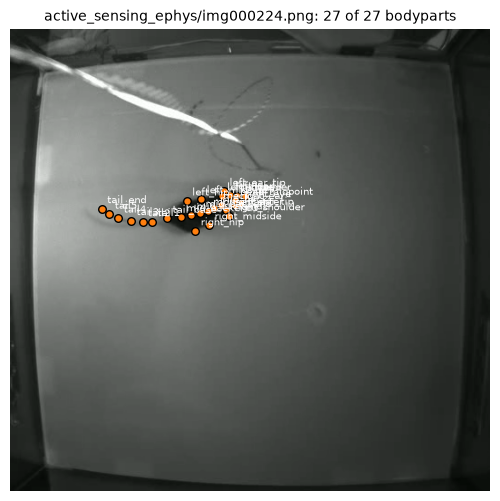

In [27]:
LABELS_FILE = "labeled-data/active_sensing_ephys/CollectedData_celia.h5"

key = (HumanLabels * UnitRevision * Unit & dlc_project & {"relative_path": LABELS_FILE}).keys()[0]
xy = (HumanLabels & key).fetch1("xy")
bodyparts = (HumanLabels.Keypoint & key).to_arrays("bodypart", order_by="keypoint_index")
labeled = ~np.isnan(xy).any(axis=-1)

frame = int(labeled.sum(axis=1).argmax())  # the frame with the most labeled bodyparts
folder, dataset, image = (HumanLabels.Frame & key & {"frame_index": frame}).fetch1("folder", "dataset", "image")
points, shown = xy[frame], labeled[frame]

fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(plt.imread(PROJECT / folder / dataset / image))
ax.scatter(points[shown, 0], points[shown, 1], s=30, c="tab:orange", edgecolors="black")
for name, (x, y) in zip(bodyparts[shown], points[shown], strict=True):
    ax.annotate(name, (x, y), xytext=(4, 4), textcoords="offset points", fontsize=7, color="white")
ax.set_title(f"{dataset}/{image}: {shown.sum()} of {len(bodyparts)} bodyparts", fontsize=10)
ax.axis("off");

## 5. Running it again, and the next labeling round

Like the shared helpers, registering is safe to repeat: an unchanged project adds nothing, so a pipeline can
register all its projects on every run.

In [28]:
assert register_dlc_project(PROJECT, lab=lab).registration == written.registration

registration 1: 0 new files, 0 new labels files


Then the lab labels more frames. Two datasets arrive, as DeepLabCut leaves them, as new folders in
`labeled-data/`: the least certain frames of the live run, corrected by hand, and frames picked from a clip of the
June recording. Registering again adds only those.

In [29]:
for source in sorted(INCOMING.iterdir()):
    if not (PROJECT / "labeled-data" / source.name).exists():
        shutil.copytree(source, PROJECT / "labeled-data" / source.name)

written = register_dlc_project(PROJECT, lab=lab)
labels_files(dlc_project)

registration 2: 26 new files, 2 new labels files


lab_id,dlc_project_id,unit_id,revision_id,long_format_version,n_frames,relative_path
demo,c17ab0e8-bcb6-47fc-82d1-d97176c1f69c,1e479d96-d328-4f0f-9198-4e4c90419550,94d3b40a-5336-4ced-a9c3-0f565ed41ec4,0.0,10,labeled-data/active_sensing_ephys_first_30s/CollectedData_celia.h5
demo,c17ab0e8-bcb6-47fc-82d1-d97176c1f69c,7e4b2533-56fe-4cd1-ac86-577e1d07a6fd,f6d5e413-651c-48f7-8fb8-191f38f516db,0.0,459,labeled-data/active_sensing_ephys/CollectedData_celia.h5
demo,c17ab0e8-bcb6-47fc-82d1-d97176c1f69c,7ffdfa92-c3f3-437d-b0b9-c2e023261c11,f6e5fb68-74c9-4350-b597-8ef0f90bda02,0.0,10,labeled-data/live_20261103_090529_186/CollectedData_celia.h5


## 6. Link the labeled datasets to sessions

dlc-scene knows the project and its frames, but not which session they show. The lab knows: a dataset in
`labeled-data/` is named after the video its frames come from. That knowledge goes into a table of the lab's own,
as in [Getting started](01_getting_started.ipynb), referencing both the shared `Session` and `DlcProject`.

In [30]:
demo = SCENE_REGISTRY.get("demo") or SCENE_REGISTRY.make_schema("demo")


@demo
class LabeledDataset(dj.Manual):
    definition = """
    -> DlcProject
    dataset: varchar(255)   # folder in labeled-data/, named after its video
    ---
    -> Session
    """


SCENE_REGISTRY.activate_all()  # binds the "demo" schema

VIDEO_SESSION = {
    "active_sensing_ephys": recording,
    "active_sensing_ephys_first_30s": recording,  # a clip of the same video
    "live_20261103_090529_186": live_run,
}
LabeledDataset.insert(
    [{**dlc_project, "dataset": name, **session} for name, session in VIDEO_SESSION.items()],
    skip_duplicates=True,
)
LabeledDataset * Session.proj("session_code")

lab_id,dlc_project_id,dataset,session_id,session_code
demo,c17ab0e8-bcb6-47fc-82d1-d97176c1f69c,active_sensing_ephys,293890e7-a2e3-438a-9cfc-1538c343f50d,ephys-01_20260626_1
demo,c17ab0e8-bcb6-47fc-82d1-d97176c1f69c,active_sensing_ephys_first_30s,293890e7-a2e3-438a-9cfc-1538c343f50d,ephys-01_20260626_1
demo,c17ab0e8-bcb6-47fc-82d1-d97176c1f69c,live_20261103_090529_186,6568a8ff-6f1c-43b2-bf29-fdf40bb4ee64,ephys-01_20261103_1


## 7. Queries across the layers

Labeled frames per mouse and session:

In [31]:
frames = pd.DataFrame((HumanLabels.Frame & dlc_project).to_dicts())
sessions = pd.DataFrame(
    (LabeledDataset * Session * Session.Subject * Subject)
    .proj("session_code", "session_date", "subject_code")
    .to_dicts()
)
frames.merge(sessions, on=["dlc_project_id", "dataset"]).groupby(["subject_code", "session_code"]).size()

subject_code  session_code       
ephys-01      ephys-01_20260626_1    469
              ephys-01_20261103_1     10
dtype: int64

The keypoints labeled on a mouse, from all projects with a dataset of its sessions:

In [32]:
of_mouse = LabeledDataset * Session.Subject & subject_key("ephys-01", lab=lab)
(KeypointSpec.Bodypart & of_mouse).proj("bodypart")

lab_id,dlc_project_id,keypoint_spec_id,bodypart_index,bodypart
demo,c17ab0e8-bcb6-47fc-82d1-d97176c1f69c,8ef14a29-04f2-4912-b056-1a223429fa1e,0,nose
demo,c17ab0e8-bcb6-47fc-82d1-d97176c1f69c,8ef14a29-04f2-4912-b056-1a223429fa1e,1,left_ear
demo,c17ab0e8-bcb6-47fc-82d1-d97176c1f69c,8ef14a29-04f2-4912-b056-1a223429fa1e,2,right_ear
demo,c17ab0e8-bcb6-47fc-82d1-d97176c1f69c,8ef14a29-04f2-4912-b056-1a223429fa1e,3,left_ear_tip
demo,c17ab0e8-bcb6-47fc-82d1-d97176c1f69c,8ef14a29-04f2-4912-b056-1a223429fa1e,4,right_ear_tip
demo,c17ab0e8-bcb6-47fc-82d1-d97176c1f69c,8ef14a29-04f2-4912-b056-1a223429fa1e,5,left_eye
demo,c17ab0e8-bcb6-47fc-82d1-d97176c1f69c,8ef14a29-04f2-4912-b056-1a223429fa1e,6,right_eye
demo,c17ab0e8-bcb6-47fc-82d1-d97176c1f69c,8ef14a29-04f2-4912-b056-1a223429fa1e,7,neck
demo,c17ab0e8-bcb6-47fc-82d1-d97176c1f69c,8ef14a29-04f2-4912-b056-1a223429fa1e,8,mid_back
demo,c17ab0e8-bcb6-47fc-82d1-d97176c1f69c,8ef14a29-04f2-4912-b056-1a223429fa1e,9,mouse_center


The tables used here, shared, dlc and the lab's own:

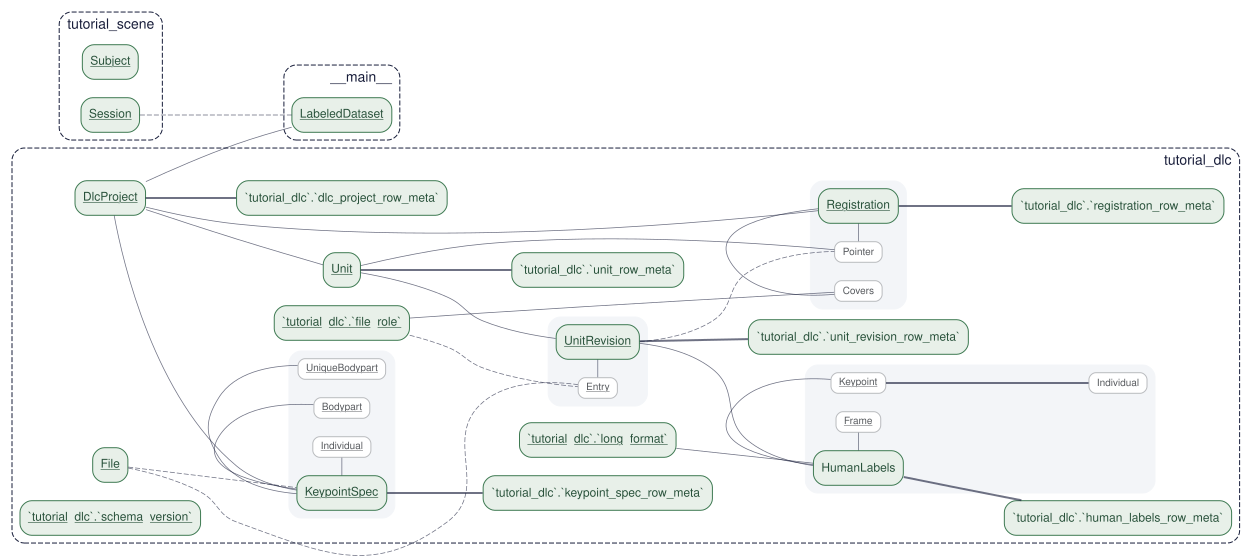

In [33]:
dj.Diagram(SCENE_REGISTRY.get("dlc")) + dj.Diagram(LabeledDataset) + dj.Diagram(Session) + dj.Diagram(Subject)

## Where next

- [An existing lab: MLAI and MouseAR](03_mlai_mouse_ar.ipynb): a real lab pipeline on the shared tables.
- dlc-scene records the project's files by hash; it does not keep copies. To keep the labels files themselves,
  register them in a store with `register_file`, as in [Getting started](01_getting_started.ipynb).
- Models and their predictions on session videos are not registered yet.

To start over, drop the tutorial databases, delete the working copy and restart the kernel:

```python
from tutorial_utils import drop_tutorial_schemas

drop_tutorial_schemas()
shutil.rmtree(work_dir)
```